#**[개념]**

###**앙상블 학습**

* 앙상블 학습을 통한 분류: 여러 개의 분류기를 생성 & 그 예측을 결합 -> 보다 정확한 최종 예측을 도출하는 기법
* 목표: 단일 분류기보다 신뢰성 높은 예측값 얻는 것
* 유형: 보팅 / 배깅 / 부스팅 / 스태깅 / ..

(1) 보팅
* 일반적으로 서로 다른 알고리즘을 가진 분류기를 결합
* 여러 개의 분류기가 투표를 통해 최종 예측 결과 결정

(2) 배깅
* 각각의 분류기가 모두 같은 유형의 알고리즘 기반 (데이터 샘플링은 다르게)
* 여러 개의 분류기가 투표를 통해 최종 예측 결과 결정
* ex) 랜덤 포레스트 알고리즘

(3) 부스팅
* 여러 개의 분류기가 순차적으로 학습 수행, 앞에서 학습한 분류기가 예측이 틀린 데이터에 대해 올바르게 예측할 수 있도록 다음 분류기에 가중치 부여하며 학습 & 예측 진행
* 대표적인 부스팅 모델: 그래디언트 부스트, XGBoost, LightGBM

(4) 스태킹
* 여러 가지 다른 모델의 예측 결괏값을 다시 학습 데이터로 만들어 다른 모델로 재학습시켜 결과 예측

**1. 보팅 유형 - 하드 보팅과 소프트 보팅**

* 일반적으로 소프트 보팅이 예측 성능이 좋아서 더 많이 사용됨

(1) 하드 보팅
* 예측한 결괏값들 중 다수의 분류기가 결정한 예측값을 최종 보팅 결괏값으로 선정

(2) 소프트 보팅
* 분류기들의 레이블 값 결정 확률을 평균해서 이들 중 확률이 가장 높은 레이블 값을 최종 보팅 결괏값으로 선정

**2. 보팅 분류기 - VotingClassifier()**

* VotingClassifier 클래스의 주요 생성 인자: estimators, voting
* estimators: 리스트 값으로 보팅에 사용될 여러 개의 Classifier 객체들을 튜플 형식으로 입력받음
* voting: 'hard' (하드 보팅), 'soft' (소프트 보팅). 기본은 hard

@ load_breast_cancer(): 위스콘신 유방암 데이터 세트 생성

### **랜덤 포레스트 - RandomForestClassifier()**

* 결정 트리가 기반 알고리즘
* 여러 개의 결정 트리 분류기가 전체 데이터에서 배깅 방식으로 각자의 데이터를 샘플링해 개별적으로 학습을 수행 -> 최종적으로 모든 분류기가 보팅을 통해 예측 결정
* 부트스트래핑: 여러 개의 데이터 세트를 중첩되게 분리하는 것. 개별 트리가 학습하는 데이터 세트는 전체 데이터에서 일부가 중첩되게 샘플링된 데이터 세트 (데이터 세트의 데이터 건수는 전체 데이터 건수와 동일)

**1. 랜덤포레스트 하이퍼 파라미터 및 튜닝**

(1) 랜덤포레스트 하이퍼 파라미터
* n_estimators: 랜덤 포레스트에서 결정 트리의 개수 지정. 디폴트는 10
* max_features: 결정 트리에 사용된 max_features 파라미터와 같음. 디폴트는 전체 피처 개수의 sqrt
* max_depth 나 min_samples_leaf, min_sampels_split와 같이 결정 트리에서 과적합 개선하기 위해 사용되는 파라미터도 똑같이 적용될 수 있음

(2) 튜닝
* 랜덤 포레스트는 CPU 병렬 처리도 효과적으로 수행되어 빠른 학습 가능
  (멀티 코어 환경에서 RandomForestClassifier 생성자와 GridSearchCV 생성 시 n_jobs=-1 파라미터 추가하면 모든 CPU 코어 이용해 학습 가능)

@ feature_importances_ 속성: DecisionTreeClassifier와 똑같이, RandomForestClassifier도 알고리즘이 선택한 피처의 중요도 확인 가능

### **GBM - GradientBoostingClassifier()**

* 부스팅 알고리즘: 여러 개의 약한 학습기를 순차적으로 학습 - 예측하며 잘못 예측한 데이터에 가중치 부여를 통해 오류를 개선해 나가며 학습하는 방식
* 부스팅의 대표적인 구현: AdaBoost, 그래디언트 부스트

(1) 에이다 부스트 (AdaBoost)
* 오류 데이터에 가중치를 부여하며 부스팅을 수행하는 대표적인 알고리즘
* 개별 약한 학습기는 각각 가중치를 부여해 결합

(2) GBM
* 가중치 업데이트 시 경사 하강법 이용
* 분류/회귀 모두가능
* 일반적으로 랜덤 포레스트보다 예측 성능이 조금 뛰어난 경우가 많음
* 과적합에도 강한 뛰어난 예측 성능을 가짐
* 다만 수행 시간이 오래 걸리고, 하이퍼 파라미터 튜닝 노력도 더 필요
* GBM 기반 ML 패키지: XGBoost, LightGBM, ...

[경사 하강법]
* 오류 값: 실제 값 - 예측값
* 분류의 실제 결괏값을 y, 피처를 x1, x2, ..., xn, 피처에 기반한 예측 함수는 F(x)라고 하면 오류식 h(x) = y - F(x)
* 오류식을 최소화하는 방향성을 갖고 반복적으로 가중치 값을 업데이트하는 것 (반복 수행을 통해 오류를 최소화할 수 있도록 가중치의 업데이트 값을 도출하는 기법)

**1. GBM 하이퍼 파라미터**

(1) loss: 경사 하강법에서 사용할 비용 함수 지정 (기본값: deviance)

(2) learning_rate
* GBM이 학습 진행할 때마다 적용하는 학습률. Weak learner가 순차적으로 오류 값을 보정해 나가는 데 적용하는 계수
* 0~1 사이 값 지정 (기본값: 0.1)
* n_estimators와 상호 보완적으로 조합해 사용. learning_rate를 작게, n_estimator를 크게 하면 더 이상 성능이 좋아지지 않는 한계점까지는 예측 성능이 조금씩 좋아질 수 있음. but 수행 시간이 너무 오래 걸리고, 예측 성능 역시 현격히 좋아지는 것은 X

(3) n_estimators
* weak learner의 개수 (기본값: 100)
* weak learner가 순차적으로 오류 보정 -> 개수 많을수록 예측 성능이 일정 수준까지는 좋아질 수 있음. but 개수 많을수록 수행 시간 오래 걸림)

(4) subsample
* weak learner가 학습에 사용하는 데이터의 샘플링 비율
* 과적합 염려되는 경우 subsample을 1보다 작은 값으로 설정 (기본값: 1)

### **XGBoost**

* GBM 기반. GBM 단점인 느린 수행 시간 및 과적합 규제 부재 등의 문제 해결
* 병렬 CPU 환경에서 병렬 학습 가능
* 뛰어난 예측 성능, 자체 내장된 교차 검증, 결손값 자체 처리 등의 장점이 있음
* 조기 중단 기능: 수행 속도 향상시키기 위한 기능

@ plot_importance()
* 파라미터: 학습 완료된 모델 객체 및 맷플롯립의 ax 객체 입력
* xgboost 패키지에 내장된 시각화 기능
* 피처의 중요도를 막대그래프 형식으로 나타냄
* 기본 평가 지표로 f스코어(해당 피처가 트리 분할 시 얼마나 자주 사용되었는지)를 기반으로 해당 피처의 중요도를 나타냄
* 넘파이 기반 피처 데이터로 학습 시 Y축의 피처명 나열할 때 f0, f1처럼 피처 순서별로 f자 뒤에 순서 붙여 피처명 나타내야 함

@ to_graphviz()
* 트리 기반 규칙 구조 시각화 가능
* xgboost.to_graphviz() 내에 파라미터로 학습 완료된 모델 객체, Graphviz가 참조할 파일명 입력

(1) 파이썬 래퍼 XGBoost 모듈
* 초기의 독자적인 XGBoost 프레임워크 기반의 XGBoost (초기에는 사이킷런과 호환되지 않는 패키지였음) -> 고유의 API와 하이퍼 파라미터 이용
* XGBoost만의 전용 데이터 객체인 DMatrix 사용. Numpy or Pandas로 되어 있는 데이터 세트를 모두 전용 데이터 객체인 DMatrix로 생성하여 모델에 입력해 주어야 함 (DMatrix의 주요 입력 파라미터는 data & label)

(2) 사이킷런 래퍼 XGBoost 모듈
* 사이킷런과 연동되는 모듈

**1. 파이썬 래퍼 XGBoost 하이퍼 파라미터**

* XGBoost의 하이퍼 파라미터는 주로 딕셔너리 형태로 입력
* 하이퍼 파라미터를 xgboost 모듈의 train() 함수에 파라미터로 전달(Estimator의 생성자를 하이퍼 파라미터로 전달하는 사이킷런과 다름)

@ cv()
* 데이터 세트에 대한 교차 검증 수행 후 최적 파라미터 제공
* 반환값은 DataFrame 형태

---

* xgboost.cv(params, dtrain, num_boost_round, nfold, stratified, metrics, early_stopping_rounds, ...)
* params (dict): 부스터 파라미터
* dtrain (DMatrix): 학습 데이터
* num_boost_round: 부스팅 반복 횟수
* nfold: CV 폴드 개수
* stratified (bool): CV 수행 시 층화 표본 추출 수행 여부
* metrics (string / list): CV 수행 시 모니터링할 성능 평가 지표
* early_stopping_rounds: 조기 중단 활성화

---

(1) 파이썬 래퍼 XGBoost 하이퍼 파라미터의 유형
* 대부분의 하이퍼 파라미터는 Booster 파라미터에 속함

1. 일반 파라미터: 일반적으로 실행 시 스레드의 개수나 silent 모드 등의 선택을 위한 파라미터 *ex) booster(gbtree or gblinear 선택), silent(출력 메시지 나타냄 여부. 0 or 1(나타내지 x)), nthread(CPU 실행 스레드 개수 조정)*
  
2. 부스터 파라미터: 트리 최적화, 부스팅, regularization 등과 관련된 파라미터 *ex) eta[default=0.3, alias: learning_rate] (GBM의 학습률과 같은 파라미터), num_boost_rounds(GBM의 n_estimators와 같은 파라미터)*

3. 학습 태스크 파라미터: 학습 수행 시 객체 함수, 평가를 위한 지표 등을 설정하는 파라미터 *ex) objective(최솟값을 가져야 할 손실 함수 정의), eval_metric(검증에 사용되는 함수 정의. 기본값은 회귀인 경우 rmse, 분류일 경우 error)*

* 과적합 문제가 심각하다면 고려할 것

1. eta 값 낮추기(0.01 ~ 0.1). eta 값 낮추면 num_round(또는 n_estimators)는 반대로 높여줘야 함

2. max_depth 값 낮추기

3. min_child_weight 값 높이기

4. gamma 값 높이기

5. subsample과 colsample_bytree 조정

---

(2) 파이썬 래퍼 XGBoost 조기 중단
 * xgboost의 train() 함수에 early_stopping_rounds 파라미터 입력하여 설정. 조기 중단 수행하려면 평가용 데이터 세트 지정 & eval_metric 설정 필요. (평가용 데이터 세트는 평가용 데이터 세트를 명기하는 개별 튜플 가지는 리스트 형태로 설정)

**2.사이킷런 래퍼 XGBoost의 개요 및 적용**

* XGBClassifier (분류를 위한 래퍼 클래스) / XGBRegressor (회귀를 위한 래퍼 클래스)

(1) 사이킷런 래퍼 XGBoost의 하이퍼 파라미터
* eta -> learning_rate
* sub_sample -> subsample
* lambda -> reg_lambda
* alpha -> reg_alpha

(2) 사이킷런 래퍼 XGBoost에서의 조기 중단
* 조기 중단 관련 파라미터를 fit()에 입력

* 조기 중단 관련 파라미터
1. early_stopping_rounds: 평가 지표가 향상될 수 있는 반복 횟수 정의
2. eval_metric: 조기 중단을 위한 평가 지표
3. eval_set: 성능 평가를 수행할 데이터 세트. 학습과 검증을 의미하는 문자열 필요 X.  

#**[필사]**

In [1]:
import pandas as pd

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

data_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
data_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [2]:
# 개별 모델은 로지스틱 회귀와 KNN임.
lr_clf = LogisticRegression(solver='liblinear')
knn_clf = KNeighborsClassifier(n_neighbors=8)

# 개별 모델을 소프트 보팅 기반의 앙상블 모델로 구현한 분류기
vo_clf = VotingClassifier( estimators=[('LR', lr_clf), ('KNN', knn_clf)], voting='soft')

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=156)

# VotingClassifier 학습/예측/평가
vo_clf.fit(X_train, y_train)
pred = vo_clf.predict(X_test)
print('Voting 분류기 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

# 개별 모델의 학습/예측/평가
classifiers = [lr_clf, knn_clf]
for classifier in classifiers:
  classifier.fit(X_train, y_train)
  pred = classifier.predict(X_test)
  class_name=classifier.__class__.__name__
  print('{0} 정확도: {1:.4f}'.format(class_name, accuracy_score(y_test, pred)))

Voting 분류기 정확도: 0.9561
LogisticRegression 정확도: 0.9474
KNeighborsClassifier 정확도: 0.9386


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

def get_new_feature_name_df(old_feature_name_df):
  feature_dup_df=pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(), columns=['dup_cnt'])
  feature_dup_df=feature_dup_df.reset_index()
  new_feature_name_df=pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how='outer')
  new_feature_name_df['column_name']=new_feature_name_df[['column_name', 'dup_cnt']].apply(lambda x: x[0]+'_'+str(x[1]) if x[1]>0 else x[0], axis=1)
  new_feature_name_df=new_feature_name_df.drop(['index'], axis=1)
  return new_feature_name_df

def get_human_dataset():
  feature_name_df=pd.read_csv('features.txt', sep='\s+', header=None, names=['column_index', 'column_name'])
  new_feature_name_df = get_new_feature_name_df(feature_name_df)
  feature_name = new_feature_name_df.iloc[:, 1].values.tolist()
  X_train = pd.read_csv('X_train.txt',sep=r'\s+', names=feature_name)
  X_test = pd.read_csv('X_test.txt', sep=r'\s+', names=feature_name)
  y_train = pd.read_csv('y_train.txt',sep=r'\s+', header=None, names=['action'])
  y_test = pd.read_csv('y_test.txt', sep=r'\s+', header=None, names=['action'])
  return X_train, X_test, y_train, y_test

# 결정 트리에서 사용한 get_human_dataset()를 이용해 학습/테스트용 DataFrame 반환
X_train, X_test, y_train, y_test = get_human_dataset()

# 랜덤 포레스트 학습 및 별도의 테스트 세트로 예측 성능 평가
rf_clf = RandomForestClassifier(random_state=0, max_depth=8)
rf_clf.fit(X_train, y_train)
pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print('랜덤 포레스트 정확도: {0:.4f}'.format(accuracy))

<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_43647/2804660878.py:16: SyntaxWarning: invalid escape sequence '\s'
  feature_name_df=pd.read_csv('features.txt', sep='\s+', header=None, names=['column_index', 'column_name'])


랜덤 포레스트 정확도: 0.9220


In [4]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [8, 16, 24],
    'min_samples_leaf': [1, 6, 12],
    'min_samples_split': [2, 8, 16]
}

# RandomForestClassifier 객체 생성 후 GridSearchCV 수행
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
grid_cv = GridSearchCV(rf_clf, param_grid=params, cv=2, n_jobs=-1)
grid_cv.fit(X_train, y_train)

print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 16, 'min_samples_leaf': 6, 'min_samples_split': 16}
최고 예측 정확도: 0.9157


추출된 최적 하이퍼 파라미터로 RandomForestClassifier를 학습시킨 뒤 테스트 데이터 세트에서 예측 성능 측정

In [5]:
rf_clf1 = RandomForestClassifier(n_estimators=100, min_samples_leaf=6, max_depth=16, min_samples_split=2, random_state=0)
rf_clf1.fit(X_train, y_train)
pred = rf_clf1.predict(X_test)
print('예측 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

예측 정확도: 0.9253


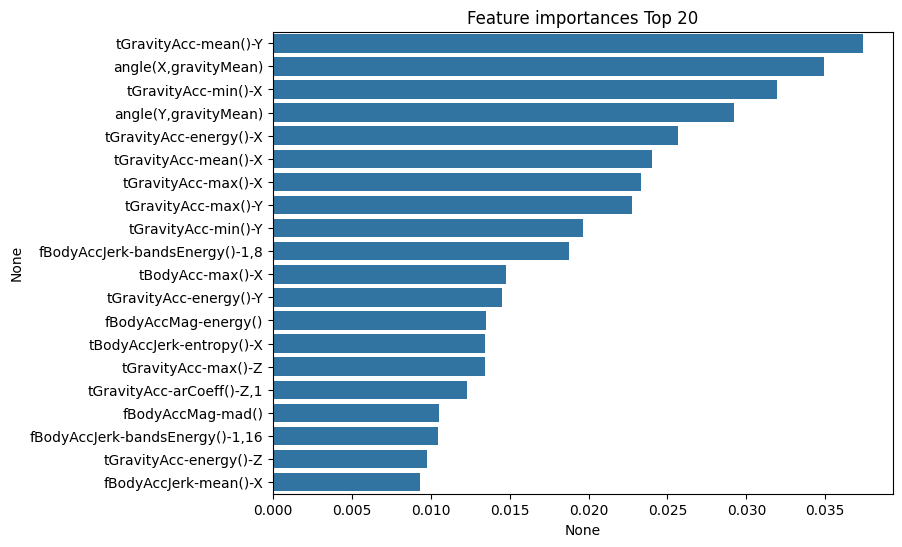

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]

plt.figure(figsize=(8,6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y=ftr_top20.index)
plt.show()

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
import time
import warnings
warnings.filterwarnings('ignore')

X_train, X_test, y_train, y_test = get_human_dataset()

# GBM 수행 시간 측정을 위함. 시작 시간 설정.
start_time = time.time()

gb_clf = GradientBoostingClassifier(random_state=0)
gb_clf.fit(X_train, y_train)
gb_pred = gb_clf.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

print('GBM 정확도: {0:.4f}'.format(gb_accuracy))
print('GBM 수행 시간: {0:.1f} 초'.format(time.time() - start_time))

GBM 정확도: 0.9379
GBM 수행 시간: 1457.1 초


In [8]:
#pip install xgboost==1.5.0

In [9]:
import xgboost as xgb
from xgboost import XGBClassifier

In [10]:
import xgboost

print(xgboost.__version__)

3.4.1


###[파이썬 래퍼 XGBoost 적용 - 위스콘신 유방암 예측]

사용하는 데이터
* 종양의 크기, 모양 등의 다양한 속성값을 기반으로 악성 종양인지 양성 종양인지 분류한 데이터 세트
* 양성 종양은 비교적 성장 속도 느리고 전이 X. 악성 종양은 주위조직에 침입하며 빠르게 성장하고 신체 각 부위에 확산 or 전이되어 생명 위협

In [11]:
import xgboost as xgb
from xgboost import plot_importance
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

dataset = load_breast_cancer()
features= dataset.data
labels = dataset.target

cancer_df = pd.DataFrame(data=features, columns=dataset.feature_names)
cancer_df['target']= labels
cancer_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


타깃 레이블: 악성이 0, 양성이 1

In [12]:
print(dataset.target_names)
print(cancer_df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


In [13]:
# cancer_df에서 feature용 DataFrame과 Label용 Series 객체 추출
# 맨 마지막 칼럼이 Label임. Feature용 DataFrame은 cancer_df의 첫번째 칼럼에서 맨 마지막 두번째 칼럼까지를 :-1 슬라이싱으로 추출.
X_features = cancer_df.iloc[:, :-1]
y_label = cancer_df.iloc[:, -1]

# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features, y_label, test_size=0.2, random_state=156)

# 위에서 만든 X_train, y_train을 다시 쪼개서 90%는 학습과 10%는 검증용 데이터로 분리 (XGBoost가 제공하는 기능 수행해 보고자)
X_tr, X_val, y_tr, y_val=train_test_split(X_train, y_train, test_size=0.1, random_state=156)

print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)

(455, 30) (114, 30)
(409, 30) (46, 30)


전체 569개의 데이터 세트에서 최종 학습용 409개, 검증용 46개, 테스트용 114개

In [14]:
# 만약 구버전 XGBoost에서 DataFrame으로 DMatrix 생성이 안 될 경우 X_train.values로 넘파이 변환.
# 학습, 검증, 테스트용 DMatrix를 생성.
dtr = xgb.DMatrix(data=X_tr, label=y_tr)
dval = xgb.DMatrix(data=X_val, label=y_val)
dtest = xgb.DMatrix(data=X_test, label=y_test)

In [15]:
params = { 'max_depth':3,
           'eta': 0.05,
           'objective':'binary:logistic',
           'eval_metric':'logloss'
          }
num_rounds = 400

* 예제 데이터가 0 또는 1 이진 분류이므로 목적함수(objective)는 이진 로지스틱(binary:logistic)
* 오류 함수 평가 성능 지표는 logloss
* num_rounds(부스팅 반복 횟수)는 400회

In [16]:
# 학습 데이터 셋은 'train' 또는 평가 데이터 셋은 'eval'로 명기합니다.
eval_list = [(dtr, 'train'), (dval, 'eval')] # 또는 eval_list = [(dval, 'eval')] 만 명기해도 무방.

# 하이퍼 파라미터와 early stopping 파라미터를 train() 함수의 파라미터로 전달
xgb_model = xgb.train(params = params, dtrain=dtr, num_boost_round=num_rounds, early_stopping_rounds=50, evals=eval_list)

[0]	train-logloss:0.62473	eval-logloss:0.63225
[1]	train-logloss:0.58662	eval-logloss:0.60730
[2]	train-logloss:0.55210	eval-logloss:0.58562
[3]	train-logloss:0.52058	eval-logloss:0.56615
[4]	train-logloss:0.49155	eval-logloss:0.54542
[5]	train-logloss:0.46491	eval-logloss:0.53043
[6]	train-logloss:0.43969	eval-logloss:0.51101
[7]	train-logloss:0.41648	eval-logloss:0.49373
[8]	train-logloss:0.39503	eval-logloss:0.47735
[9]	train-logloss:0.37517	eval-logloss:0.46266
[10]	train-logloss:0.35673	eval-logloss:0.44940
[11]	train-logloss:0.33938	eval-logloss:0.43843
[12]	train-logloss:0.32276	eval-logloss:0.42597
[13]	train-logloss:0.30774	eval-logloss:0.41552
[14]	train-logloss:0.29356	eval-logloss:0.40645
[15]	train-logloss:0.27989	eval-logloss:0.39635
[16]	train-logloss:0.26709	eval-logloss:0.38696
[17]	train-logloss:0.25531	eval-logloss:0.37957
[18]	train-logloss:0.24381	eval-logloss:0.37218
[19]	train-logloss:0.23343	eval-logloss:0.36735
[20]	train-logloss:0.22322	eval-logloss:0.36096
[2

* 평가용 데이터 세트는 개별 튜플에서 명기하여 설정한 후 train() 함수의 evals 인자값으로 입력
* Xgboost 학습 반복 시마다 evals에 설정된 데이터 세트에 대해 평가 지표 결과 출력
* train()은 학습이 완료된 모델 객체를 반환

In [17]:
pred_probs = xgb_model.predict(dtest)
print('predict() 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨')
print(np.round(pred_probs[:10], 3))

# 예측 확률이 0.5보다 크면 1, 그렇지 않으면 0으로 예측값 결정하여 List 객체인 preds에 저장
preds = [ 1 if x > 0.5 else 0 for x in pred_probs ]
print('예측값 10개만 표시:',preds[:10])

predict() 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨
[0.933 0.006 0.687 0.123 0.974 0.999 0.998 0.998 0.996 0.001]
예측값 10개만 표시: [1, 0, 1, 0, 1, 1, 1, 1, 1, 0]


* train() 함수를 호출해 학습 완료된 모델 객체는 예측을 위해 predict() 메서드 이용.
* xgboost의 predict()는 예측 결과를 추정할 수 있는 확률 값을 반환 -> 예측 값 결정하는 로직 추가해야 함

In [23]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def get_clf_eval(y_test, pred, pred_proba):
  confusion=confusion_matrix(y_test,pred)
  accuracy=accuracy_score(y_test,pred)
  precision=precision_score(y_test,pred)
  recall=recall_score(y_test,pred)
  f1=f1_score(y_test,pred)
  roc_auc=roc_auc_score(y_test,pred)
  print('오차행렬')
  print(confusion)
  print('정확도:{0:.4f}, 정밀도:{1:.4f}, 재현율:{2:.4f}, F1:{3:.4f}, AUC:{4:.4f}'.format(accuracy,precision,recall,f1, roc_auc))

In [24]:
get_clf_eval(y_test, preds, pred_probs)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649, 정밀도:0.9740, 재현율:0.9740, F1:0.9740, AUC:0.9600


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

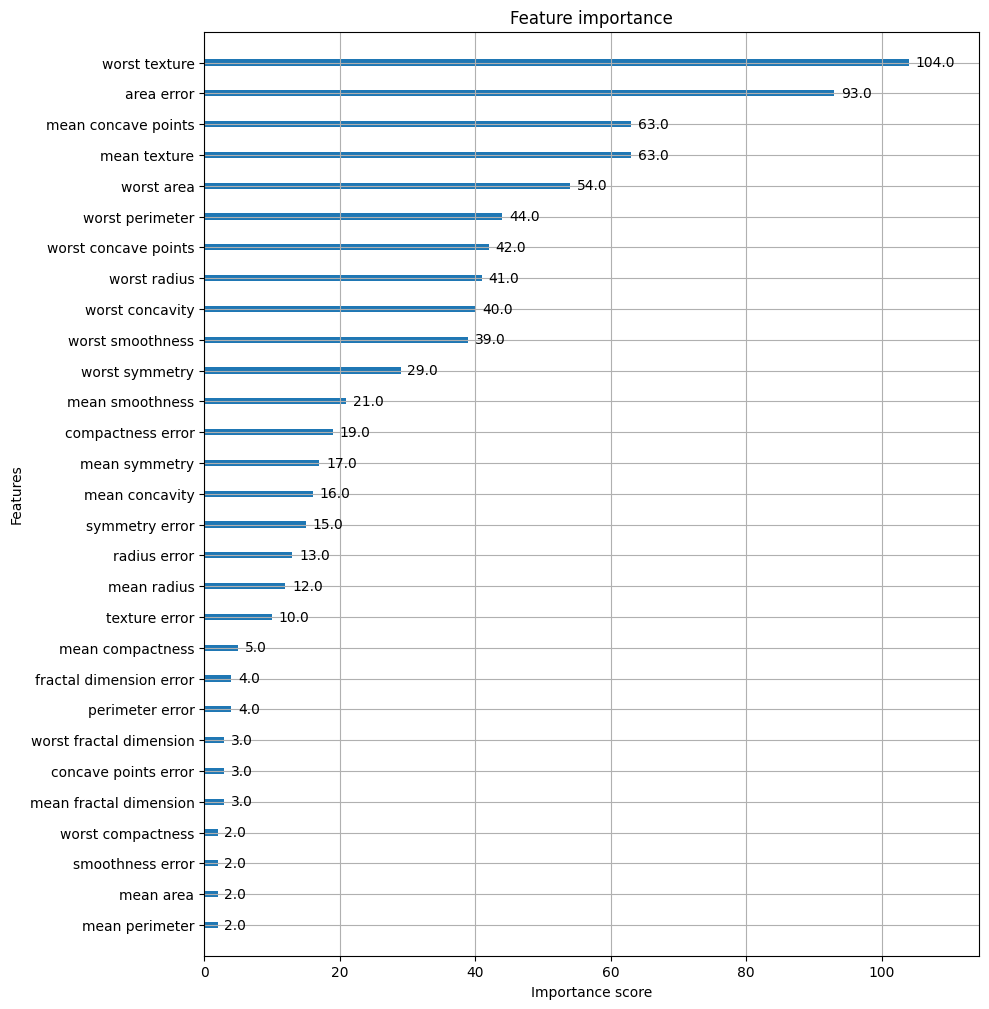

In [25]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax)

In [26]:
# 사이킷런 래퍼 XGBoost 클래스인 XGBClassifier 임포트
from xgboost import XGBClassifier

# Warning 메시지를 없애기 위해 eval_metric 값을 XGBClassifier 생성 인자로 입력.
xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, eval_metric='logloss')
xgb_wrapper.fit(X_train, y_train, verbose=True)
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

In [27]:
get_clf_eval(y_test, w_preds, w_pred_proba)

오차행렬
[[35  2]
 [ 1 76]]
정확도:0.9737, 정밀도:0.9744, 재현율:0.9870, F1:0.9806, AUC:0.9665


파이썬 래퍼 XGBoost보다 더 좋은 평가 결과가 나옴. 데이터 세트의 개수가 워낙 작은데 이전에는 조기 중단을 위해 최초 학습 데이터를 다시 학습용과 평가용으로 분리하면서 최종 학습 데이터 건수가 작아졌기 때문이라고 추정 -> 데이터 세트가 적은 경우, 전반적으로 검증 데이터 분리 or 교차 검증 등 적용 시 성능 수치 불안정

In [29]:
from xgboost import XGBClassifier

xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=50, eval_metric='logloss')
evals = [(X_tr, y_tr), (X_val, y_val)]
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

ws50_preds = xgb_wrapper.predict(X_test)
ws50_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

In [30]:
get_clf_eval(y_test, ws50_preds, ws50_pred_proba)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649, 정밀도:0.9740, 재현율:0.9740, F1:0.9740, AUC:0.9600


In [31]:
# early_stopping_rounds를 10으로 설정하고 재학습.
xgb_wrapper=XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=10, eval_metric='logloss')
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

ws10_preds = xgb_wrapper.predict(X_test)
ws10_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]
get_clf_eval(y_test, ws10_preds, ws10_pred_proba)

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

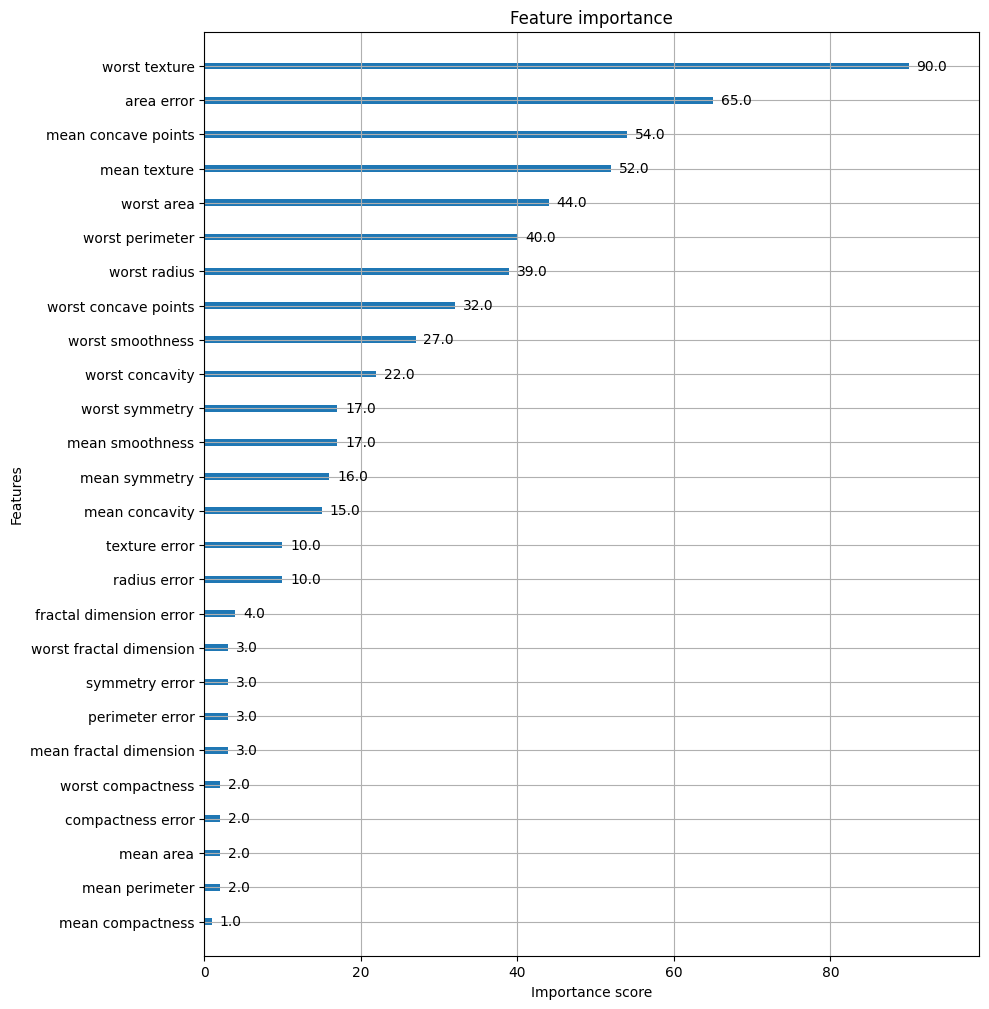

In [32]:
from ast import increment_lineno
from xgboost import plot_importance
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
# 사이킷런 래퍼 클래스를 입력해도 무방.
plot_importance(xgb_wrapper, ax=ax)